                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.000125         0.002826   
pickup_longitude      0.000125          1.000000        -0.811435   
pickup_latitude       0.002826         -0.811435         1.000000   
dropoff_longitude    -0.002534          0.835878        -0.766797   
dropoff_latitude      0.000715         -0.850520         0.683972   
passenger_count       0.011995         -0.000582        -0.001742   
hour                 -0.013304          0.003668        -0.004779   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                -0.002534          0.000715         0.011995   
pickup_longitude            0.835878         -0.850520        -0.000582   
pickup_latitude            -0.766797          0.683972        -0.001742   
dropoff_longitude           1.000000         -0.913666         0.000271   
dropoff_latitude           -0.913666          1.000000        -0.000911 

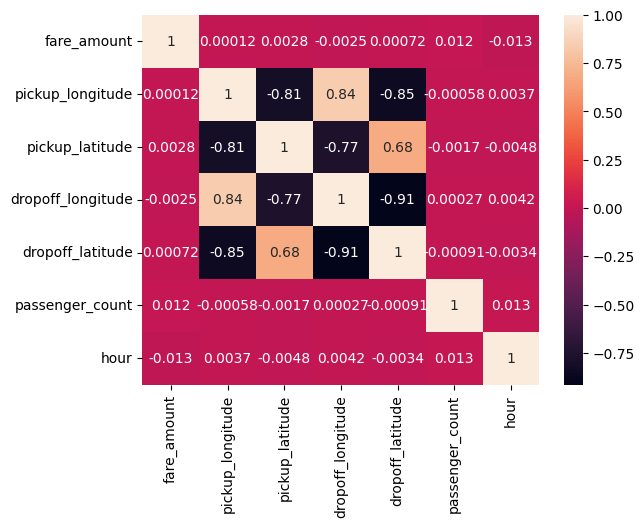


 Linear Regression
R2 Score: 0.0004404112193427956
RMSE: 4.128596505319262
MAE: 3.2826076453454256

 Ridge Regression
R2 Score: 0.00044040895669494873
RMSE: 4.1285965099921
MAE: 3.2826076448629222

 Lasso Regression
R2 Score: -6.966961426146945e-05
RMSE: 4.129649793874438
MAE: 3.283004274011716


In [1]:
#pip install pandas numpy matplotlib seaborn scikit-learn


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.pipeline import make_pipeline

# 1. Load dataset
df = pd.read_csv("uber.csv")

# Preprocessing
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")
df = df.dropna()
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])

df["hour"] = df["pickup_datetime"].dt.hour
df = df.drop(columns=["pickup_datetime"])

# Remove invalid values
df = df[(df["fare_amount"] > 0) &
        (df["passenger_count"] > 0)]

# 2. Identify and remove outliers using IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

df = df[(df["fare_amount"] >= Q1 - 1.5*IQR) &
        (df["fare_amount"] <= Q3 + 1.5*IQR)]

# 3. Check correlation
print(df.corr(numeric_only=True))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

# 4. Split data
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Apply regression models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge()),
    "Lasso Regression": make_pipeline(StandardScaler(), Lasso())
}

# 6. Evaluate models
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print("\n", name)
    print("R2 Score:", r2_score(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
    print("MAE:", mean_absolute_error(y_test, pred))
